# 01 — Exploration du corpus : Majallat al-Shughl (مجلة الشغل, 2019)

**Objectif.** Vérifier que le PDF est exploitable avant toute extraction : pages, qualité de l'OCR par langue, numérotation des articles, abrogations, et préparation d'un échantillon de contrôle.

**Source.** Édition 2019 du Code du travail tunisien (مجلة الشغل), Imprimerie officielle (IORT). Le PDF contient **deux parties** :
- les pages **1 à 136** : le Code en arabe (pages 9 à 136 pour les articles, pages 1 à 8 : liminaires et loi de promulgation de 1966) ;
- les pages **137 à 141** : index en arabe ;
- les pages **142 à 291** : la **version française** du Code (« Article 426.- … »). Elle est imprimée **à l'envers** : le numéro d'article décroît quand le numéro de page augmente (article 446 en page 146, article 84 en page 250).

Le PDF n'a pas de couche de texte exploitable : l'OCR est nécessaire. L'arabe est lu avec `ara`, le français avec `ara+fra`.

**Ce qui change par rapport à la version précédente**
1. Les pages françaises sont désormais lues avec le pack `fra` (avant, elles étaient lues en arabe et donnaient du texte illisible).
2. Le contrôle de qualité ne compte plus les lettres arabes (qui donnaient 1,00 même sur du texte illisible) : il mesure la présence de mots fréquents de chaque langue.
3. Le Code s'arrête à la page 136 : le dernier article ne « mange » plus le reste du livre.
4. Abrogations : les variantes OCR `(الفي` et `(الفغي` sont reconnues, ainsi que les plages « الفصول X إلى Y (ألغيت …) ».
5. Tête double « الفصلان X و Y (ألغيا …) » : les articles X et Y sont tous deux comptés.
6. L'échantillon de contrôle ne contient plus d'article abrogé (vérifié par une assertion).

**Prérequis.** Python 3.11+, `pip install pymupdf pandas matplotlib`, et Tesseract avec les packs **arabe et français**. Sur Windows, cocher les deux langues à l'installation.

**Emplacement.** Sur Colab, le notebook monte Google Drive, installe Tesseract (arabe et français) et propose d'importer le PDF. Tout est sauvegardé dans `MyDrive/LegalTN`. En local, il détecte la racine du projet et ouvre une boîte de dialogue pour choisir le PDF.

**Reprise.** L'OCR est résumable : les pages déjà traitées ne sont pas recalculées.

In [1]:
import os
import re
import sys
import json
import shutil
import subprocess
from collections import Counter
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path

# pymupdf : installé automatiquement s'il manque
try:
    import pymupdf
except ImportError:
    print("Installation de pymupdf...")
    subprocess.run([sys.executable, "-m", "pip", "install", "pymupdf"], check=True)
    import pymupdf

import pandas as pd
import matplotlib.pyplot as plt

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False


def trouver_racine(depart=None):
    """Remonte depuis le dossier courant jusqu'à trouver data/raw/ (racine du projet LegalTN)."""
    depart = Path(depart or Path.cwd()).resolve()
    for parent in [depart, *depart.parents]:
        if (parent / "data" / "raw").is_dir():
            return parent
    return None


if IN_COLAB:
    # Google Drive : le PDF, l'OCR et les résultats sont sauvegardés dans MyDrive/LegalTN
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/LegalTN")
    print("Dossier de sortie (Google Drive) :", ROOT)
    # Tesseract, le pack arabe et le pack français ne sont pas installés par défaut sur Colab
    subprocess.run(
        ["apt-get", "install", "-y", "-q", "tesseract-ocr", "tesseract-ocr-ara", "tesseract-ocr-fra"],
        check=True, capture_output=True,
    )
elif "LEGALTN_ROOT" in os.environ:
    ROOT = Path(os.environ["LEGALTN_ROOT"])
else:
    ROOT = trouver_racine() or (Path.cwd() / "LegalTN")
print("Racine du projet :", ROOT)

RAW_DIR = ROOT / "data/raw/arabic"
RAW_DIR.mkdir(parents=True, exist_ok=True)
PDF_NOM = "majallat_al_shughl_2019.pdf"


def importer_pdf():
    """Importe le PDF choisi par l'utilisateur et le range dans data/raw/arabic/."""
    cible = RAW_DIR / PDF_NOM
    if cible.is_file():
        print("PDF déjà présent :", cible)
        return cible

    if IN_COLAB:
        from google.colab import files
        print("Une fenêtre s'ouvre : choisissez le PDF.")
        envoyes = files.upload()
        if not envoyes:
            raise RuntimeError("Aucun fichier envoyé.")
        source = Path(next(iter(envoyes)))
    else:
        import tkinter as tk
        from tkinter import filedialog
        try:
            fenetre = tk.Tk()
        except tk.TclError as err:
            raise RuntimeError(
                f"Sélection de fichier indisponible ({err}). Copiez le PDF dans {RAW_DIR}."
            )
        fenetre.withdraw()
        fenetre.attributes("-topmost", True)
        choisi = filedialog.askopenfilename(title="Choisir le PDF", filetypes=[("PDF", "*.pdf")])
        fenetre.destroy()
        if not choisi:
            raise RuntimeError("Aucun fichier choisi.")
        source = Path(choisi)

    shutil.copy(source, cible)
    print("PDF importé :", cible)
    return cible


PDF = importer_pdf()

IMG_DIR = ROOT / "data/processed/page_images"
OCR_DIR_AR = ROOT / "data/processed/ocr_pages"      # pages 1 à 136 (langue ara)
OCR_DIR_FR = ROOT / "data/processed/ocr_pages_fr"   # pages 137 à 291 (langues ara+fra)
OUT_DIR = ROOT / "data/processed"

DPI = 300
OCR_PSM = "6"       # bloc de texte uniforme, adapté aux pages de loi
WORKERS = 2         # nombre de processus Tesseract en parallèle
TESSERACT_CMD = shutil.which("tesseract") or r"C:\Program Files\Tesseract-OCR\tesseract.exe"

PAGE_DEBUT_CODE = 9   # première page des articles (après la loi de 1966 et les liminaires)
PAGE_FIN_CODE = 136   # dernière page du Code en arabe
PAGE_DEBUT_FR = 142   # pages 137 à 141 : index en arabe ; 142 et suite : version française

os.environ["OMP_THREAD_LIMIT"] = "1"   # évite que chaque Tesseract consomme tous les cœurs

for d in (OCR_DIR_AR, OCR_DIR_FR, IMG_DIR, OUT_DIR):
    d.mkdir(parents=True, exist_ok=True)

doc = pymupdf.open(PDF)
print("PDF :", PDF.name, "| pages :", doc.page_count)

# Garde-fou : le Code du travail (IORT 2019) compte 291 pages. Un autre PDF arrêtera le notebook ici.
PAGES_ATTENDUES = 291
if doc.page_count != PAGES_ATTENDUES:
    raise RuntimeError(f"Mauvais PDF : {doc.page_count} pages au lieu de {PAGES_ATTENDUES}. Supprimez data/raw/arabic/{PDF_NOM} et les dossiers data/processed/ (page_images, ocr_pages, ocr_pages_fr, ocr_bandes), puis réimportez le bon fichier.")

Racine du projet : /home/claude/LegalTN
PDF déjà présent : /home/claude/LegalTN/data/raw/arabic/majallat_al_shughl_2019.pdf
PDF : majallat_al_shughl_2019.pdf | pages : 291


In [2]:
res = subprocess.run([TESSERACT_CMD, "--list-langs"], capture_output=True, text=True)
langues = (res.stdout + res.stderr).split()
for langue in ("ara", "fra"):
    assert langue in langues, f"Langue « {langue} » absente : installez le pack Tesseract correspondant."
print("Tesseract prêt : arabe et français disponibles.")

Tesseract prêt : arabe et français disponibles.


## 1. Inventaire du PDF

In [3]:
meta = {k: v for k, v in doc.metadata.items() if v}
print("Métadonnées :", meta)

polices = Counter()
for page in doc:
    for font in page.get_fonts():
        polices[font[3]] += 1          # font[3] = nom de base de la police
print(f"\n{len(polices)} polices distinctes ; les plus fréquentes :")
for nom, n in polices.most_common(5):
    print(f"  {nom:<40} {n} occurrences")

Métadonnées : {'format': 'PDF 1.6', 'creator': 'PScript5.dll Version 5.2.2', 'producer': 'Acrobat Distiller 10.1.1 (Windows)', 'creationDate': "D:20181029110402+01'00'", 'modDate': "D:20190507134310+01'00'"}

86 polices distinctes ; les plus fréquentes :
  KPMHCO+TTF69o00                          148 occurrences
  KPMHCP+TTF73o00                          148 occurrences
  KPMHFC+TTF63o00                          147 occurrences
  KPMHDA+TTF64o00                          146 occurrences
  JHAJHE+TT1286o00                         139 occurrences


## 2. Test de la couche texte native

Si la couche texte était exploitable, elle donnerait de l'arabe lisible. Ce test sert à justifier l'OCR.

In [4]:
ARABIC = re.compile(r"[\u0600-\u06FF]")

def ratio_arabe(texte):
    lettres = [c for c in texte if c.isalpha()]
    if not lettres:
        return 0.0
    return sum(1 for c in lettres if ARABIC.match(c)) / len(lettres)

for i in [2, 10, 100, 200]:
    texte_natif = doc[i].get_text()
    print(f"page {i+1:>3} | {len(texte_natif):>5} car. | ratio arabe {ratio_arabe(texte_natif):.2f}")
print("\nConclusion : la couche texte native n'est pas exploitable → OCR.")

page   3 |  1468 car. | ratio arabe 0.00
page  11 |  1302 car. | ratio arabe 0.00
page 101 |  1645 car. | ratio arabe 0.00
page 201 |  2219 car. | ratio arabe 0.00

Conclusion : la couche texte native n'est pas exploitable → OCR.


## 3. OCR des pages

- Pages 1 à 136 : arabe (`ara`), résultats dans `data/processed/ocr_pages/`.
- Pages 137 à 291 : arabe et français (`ara+fra`), résultats dans `data/processed/ocr_pages_fr/`. Pages 1 à 136 : le cache précédent (`ocr_pages/`) est réutilisé.

Les images 300 dpi sont dans `data/processed/page_images/`. PyMuPDF n'est pas thread-safe : le rendu se fait dans le thread principal, seul Tesseract tourne en parallèle.

In [5]:
def dossier_ocr(n):
    """Renvoie (langue Tesseract, dossier de sortie) pour la page n (numérotée à partir de 1)."""
    if n <= PAGE_FIN_CODE:
        return "ara", OCR_DIR_AR
    return "ara+fra", OCR_DIR_FR

def chemin_image(i):
    return IMG_DIR / f"p{i+1:03d}.png"

def chemin_texte(i):
    return dossier_ocr(i + 1)[1] / f"p{i+1:03d}.txt"

# 1) Rendu des pages manquantes
a_rendre = [i for i in range(doc.page_count) if not chemin_image(i).exists()]
for i in a_rendre:
    doc[i].get_pixmap(dpi=DPI, colorspace=pymupdf.csGRAY).save(chemin_image(i))
print(f"{len(a_rendre)} pages rendues")

# 2) OCR des pages non encore traitées (reprise possible)
def ocr_une_page(i):
    langue, dossier = dossier_ocr(i + 1)
    base = dossier / f"p{i+1:03d}"          # Tesseract ajoute l'extension .txt
    subprocess.run(
        [TESSERACT_CMD, str(chemin_image(i)), str(base), "-l", langue, "--psm", OCR_PSM],
        check=True, capture_output=True,
    )
    return i

a_ocriser = [i for i in range(doc.page_count) if not chemin_texte(i).exists()]
print(f"{len(a_ocriser)} pages à traiter par OCR")

with ThreadPoolExecutor(max_workers=WORKERS) as pool:
    futures = [pool.submit(ocr_une_page, i) for i in a_ocriser]
    for compte, fut in enumerate(as_completed(futures), 1):
        fut.result()                         # lève l'erreur si une page échoue
        if compte % 25 == 0:
            print(f"  {compte}/{len(a_ocriser)} pages OCR")
print("OCR terminé.")

0 pages rendues
0 pages à traiter par OCR
OCR terminé.


## 4. Normalisation pour l'analyse

La normalisation sert à la détection et à la recherche. Le texte original reste la référence pour les citations : on ne le modifie jamais.

In [6]:
AR_DIGITS = str.maketrans("٠١٢٣٤٥٦٧٨٩", "0123456789")
TASHKEEL = re.compile(r"[\u064B-\u065F\u0670]")   # voyelles et signes diacritiques

def normaliser(texte):
    texte = texte.translate(AR_DIGITS)
    texte = TASHKEEL.sub("", texte)
    texte = texte.replace("\u0640", "")           # tatwil (étirement)
    texte = re.sub(r"[إأآ]", "ا", texte)          # formes du alif
    return texte

pages_brutes = {n: chemin_texte(n - 1).read_text(encoding="utf-8") for n in range(1, doc.page_count + 1)}
print("Brut      :", pages_brutes[12][:100])
print("Normalisé :", normaliser(pages_brutes[12])[:100])

Brut      : بتقديم خدماته للطرف الآخر ويسمى مؤجرا وذلك تحت إدارة ومراقبة هذا الأخير
وبمقابل أجر.

تثبت العلاقة ا
Normalisé : بتقديم خدماته للطرف الاخر ويسمى مؤجرا وذلك تحت ادارة ومراقبة هذا الاخير
وبمقابل اجر.

تثبت العلاقة ا


### Récupération des têtes d'article perdues par l'OCR

Sur certaines pages, Tesseract ne rend pas une ligne entière : c'est souvent la tête d'article (« الفصل 20.- ») qui disparaît, alors que le corps est lu. Le contrôle visuel a confirmé que ces articles sont bien présents sur la page.

La méthode : on découpe la page en bandes horizontales (une bande = une ligne), on reconnaît **chaque bande seule** (mode `psm 13`), et on réinjecte la tête (« الفصل N.- ») lorsqu'elle manque dans le texte de la page. La tête est placée à sa position verticale. Le corps, lui, n'est pas remplacé : on ne garde que le numéro. Les résultats sont mis en cache dans `data/processed/ocr_bandes/`.

In [7]:
import numpy as np
from PIL import Image, ImageOps
from concurrent.futures import ThreadPoolExecutor

DIR_BANDES = ROOT / "data/processed/ocr_bandes"   # cache : lignes reconnues une à une
DIR_BANDES.mkdir(parents=True, exist_ok=True)

# Tête d'article reconnue seule sur sa ligne (ex. « القصل 20< »). Un « من » après le numéro = renvoi.
TETE_LIGNE = re.compile(r"^[\W\d_]*ال[فق]صل\s*(\d{1,3})(?![\d\-–])(?!\s*[\-–]+\s*\d)(?!\s*من)")  # tolère le bruit OCR ; refuse « 2-6 » et « 20 - 3 » (suffixes) et les renvois « من »

def bandes_de_texte(img, ecart=6):
    """Bandes verticales (y0, y1) contenant de l'encre : une bande = une ligne de texte."""
    a = np.asarray(img)
    actives = (a < 128).sum(axis=1) > 3
    bandes, debut = [], None
    for y, v in enumerate(actives):
        if v and debut is None:
            debut = y
        elif not v and debut is not None:
            if bandes and debut - bandes[-1][1] < ecart:
                bandes[-1] = (bandes[-1][0], y)
            else:
                bandes.append((debut, y))
            debut = None
    if debut is not None:
        bandes.append((debut, len(actives)))
    return bandes

def reconnaitre_bande(img, n, k, y0, y1):
    rogner = ImageOps.expand(img.crop((0, max(0, y0 - 8), img.width, min(img.height, y1 + 8))), border=30, fill=255)
    tmp = DIR_BANDES / f"_p{n:03d}_{k}.png"
    rogner.save(tmp)
    res = subprocess.run([TESSERACT_CMD, str(tmp), "-", "-l", "ara", "--psm", "13"],
                         capture_output=True, text=True, env={**os.environ, "OMP_THREAD_LIMIT": "1"})
    tmp.unlink(missing_ok=True)
    return res.stdout.strip()

def lignes_de_page(n):
    """Lignes reconnues une à une pour la page n (cache JSON)."""
    cache = DIR_BANDES / f"p{n:03d}.json"
    if cache.exists():
        return json.loads(cache.read_text(encoding="utf-8"))
    img = Image.open(chemin_image(n - 1)).convert("L")
    bandes = bandes_de_texte(img)
    with ThreadPoolExecutor(max_workers=WORKERS) as pool:
        textes = list(pool.map(lambda kb: reconnaitre_bande(img, n, kb[0], kb[1][0], kb[1][1]), enumerate(bandes)))
    donnees = {"hauteur": img.height,
               "bandes": [{"y0": y0, "y1": y1, "texte": t} for (y0, y1), t in zip(bandes, textes)]}
    cache.write_text(json.dumps(donnees, ensure_ascii=False), encoding="utf-8")
    return donnees

# Numéros présents ailleurs dans le Code : on ne cherche que les numéros réellement absents
texte_code_brut = "\n".join(normaliser(pages_brutes[n]) for n in range(PAGE_DEBUT_CODE, PAGE_FIN_CODE + 1))
presents_code = {int(m.group(1)) for m in re.finditer(r"^[ \t]*الفصل[ \t]*(\d{1,3})(?=[ \t.:(\-])", texte_code_brut, re.MULTILINE)}

candidats = {}   # numéro -> [(page, indice de la bande, position verticale, reste de la ligne, bandes de la page)]
for n in range(PAGE_DEBUT_CODE, PAGE_FIN_CODE + 1):
    donnees = lignes_de_page(n)
    for k, b in enumerate(donnees["bandes"]):
        texte_ligne = normaliser(b["texte"])
        m = TETE_LIGNE.match(texte_ligne)
        if m and int(m.group(1)) not in presents_code and 1 <= int(m.group(1)) <= 446:
            reste = re.sub(r"^[^؀-ۿ]*", "", texte_ligne[m.end():]).strip()
            candidats.setdefault(int(m.group(1)), []).append((n, k, b["y0"] / donnees["hauteur"], reste, donnees["bandes"]))

# On n'accepte qu'un numéro lu une seule fois : un numéro lu sur plusieurs pages est ambigu, on le signale
ambigus = {k: v for k, v in candidats.items() if len(v) > 1}
print("Numéros lus plusieurs fois, non retenus :", sorted(ambigus))

def mots_de(bande):
    return re.findall(r"[\u0600-\u06FF]{4,}", normaliser(bande["texte"]))[:3]

def chercher(mots, lignes_norm, depart):
    """Premier indice >= depart dont la ligne contient tous les mots donnés (None si absent)."""
    if len(mots) < 2:
        return None
    for i in range(depart, len(lignes_norm)):
        if all(w in lignes_norm[i] for w in mots):
            return i
    return None

def indice_insertion(lignes_norm, bandes, k, f, reste):
    """Indice de la ligne avant laquelle insérer la tête.
    Bornes : après la ligne de la bande précédente, avant la ligne de la bande suivante.
    À l'intérieur de ces bornes, on prend la ligne qui contient le début du texte de la tête."""
    depart = 0
    if k > 0:
        j = chercher(mots_de(bandes[k - 1]), lignes_norm, 0)
        if j is not None:
            depart = j + 1
    borne = None
    for suivante in bandes[k + 1:k + 4]:
        i = chercher(mots_de(suivante), lignes_norm, depart)
        if i is not None:
            borne = i
            break
    limite = borne if borne is not None else len(lignes_norm)
    mots_reste = re.findall(r"[\u0600-\u06FF]{4,}", reste)[:5]
    for a, b in zip(mots_reste, mots_reste[1:]):
        i = chercher([a, b], lignes_norm, depart)
        if i is not None and i <= limite:
            return i
    if borne is not None:
        return borne
    return round(f * len(lignes_norm))   # repli : position verticale approximative

tetes_recuperees = {}   # page -> liste de (numéro, indice de la bande, position, reste de la ligne, bandes)
for numero, lst in candidats.items():
    if len(lst) == 1:
        n, k, f, reste, bandes = lst[0]
        tetes_recuperees.setdefault(n, []).append((numero, k, f, reste, bandes))

# Réinjection : la tête et le reste de sa ligne sont insérés juste avant la ligne suivante de la page
for n in sorted(tetes_recuperees):
    for numero, k, f, reste, bandes in sorted(tetes_recuperees[n], key=lambda t: t[1]):
        lignes = pages_brutes[n].split("\n")
        lignes_norm = normaliser(pages_brutes[n]).split("\n")
        i = round(f * len(lignes_norm))   # position verticale de la ligne reconnue
        tetes_page = [(int(m.group(1)), j) for j, l in enumerate(lignes_norm)
                      for m in [re.match(r"^[ \t]*الفصل[ \t]*(\d{1,3})(?=[ \t.:(\-])", l)] if m]
        avant = [j + 1 for v, j in tetes_page if v < numero]
        apres = [j for v, j in tetes_page if v > numero]
        lo = max(avant) if avant else 0
        hi = min(apres) if apres else len(lignes_norm)
        i = min(max(i, lo), hi)   # rester entre les têtes voisines : ordre des articles respecté
        lignes.insert(i, f"الفصل {numero}.- {reste}".rstrip())
        pages_brutes[n] = "\n".join(lignes)

recuperes = sorted(num for liste in tetes_recuperees.values() for num, *_ in liste)
print(f"Têtes récupérées par reconnaissance ligne à ligne : {len(recuperes)}")
print("Pages touchées :", sorted(tetes_recuperees))
print("Numéros :", recuperes)

# Corrections d'erreurs OCR relevées sur les images (contrôle de l'échantillon).
# Appliquées au texte de travail seulement : les fichiers OCR bruts ne sont pas modifiés.
CORRECTIONS_OCR = [
    (77, "تقدام الدعوى", "تقدم الدعوى"),          # art. 201, p. 77
    (134, "ويجرون با يشان", "ويجرون بحثا بشأن"),   # art. 442, p. 134 (tête récupérée)
]
for n_page, avant, apres in CORRECTIONS_OCR:
    nb = pages_brutes[n_page].count(avant)
    assert nb == 1, f"Correction p.{n_page} : {nb} occurrence(s) de « {avant} »"
    pages_brutes[n_page] = pages_brutes[n_page].replace(avant, apres)
print(f"Corrections OCR appliquées : {len(CORRECTIONS_OCR)}")

# Export du texte de travail (après récupération des têtes et corrections) : lu par le notebook 02
(OUT_DIR / "texte_travail.json").write_text(
    json.dumps({str(n): t for n, t in pages_brutes.items()}, ensure_ascii=False), encoding="utf-8")
print("Texte de travail exporté :", OUT_DIR / "texte_travail.json")

Numéros lus plusieurs fois, non retenus : [203, 206]
Têtes récupérées par reconnaissance ligne à ligne : 21
Pages touchées : [9, 17, 27, 28, 40, 48, 56, 60, 76, 77, 79, 94, 96, 106, 110, 113, 124, 130, 131, 134, 135]
Numéros : [2, 20, 44, 48, 84, 105, 130, 147, 194, 198, 209, 285, 293, 344, 358, 370, 407, 424, 430, 442, 446]
Corrections OCR appliquées : 2
Texte de travail exporté : /home/claude/LegalTN/data/processed/texte_travail.json


## 5. Contrôle de qualité de l'OCR, page par page

Le contrôle compte les mots fréquents de chaque langue : `ara` pour l'arabe (من، في، على، الفصل…), `fra` pour le français (de، la، le، des، article…). Une page sans aucun de ces mots est signalée « ? » : c'est le cas d'un OCR illisible.

Pages par langue détectée :
langue
fr    151
ar    137
?       3

Pages dont la langue détectée ne correspond pas à l'attendu : 1
 page  caracteres langue attendu
  140        1206     fr      ar

Pages vides ou quasi vides (< 200 caractères) : [1, 8, 136, 291]


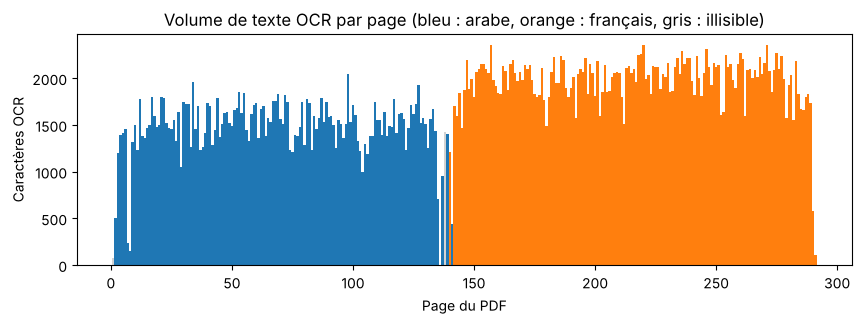

In [8]:
AR_MOTS = {normaliser(m) for m in [
    "من", "في", "على", "الى", "عن", "او", "ان", "التي", "الذي", "يجب", "بعد", "قبل",
    "هذه", "هذا", "المجلة", "الفصل", "الشغل", "العمل", "المؤجر", "الأجير",
]}
FR_MOTS = {"de", "la", "le", "les", "des", "du", "et", "est", "une", "un", "pour",
           "dans", "sont", "par", "au", "aux", "article", "code", "travail"}

def langue_page(texte):
    mots_ar = re.findall(r"[\u0600-\u06FF]+", normaliser(texte))
    mots_fr = re.findall(r"[A-Za-zÀ-ÿ]+", texte.lower())
    s_ar = sum(m in AR_MOTS for m in mots_ar) / max(len(mots_ar), 1)
    s_fr = sum(m in FR_MOTS for m in mots_fr) / max(len(mots_fr), 1)
    if max(s_ar, s_fr) < 0.03:
        langue = "?"
    else:
        langue = "ar" if s_ar > s_fr else "fr"
    return langue, round(s_ar, 3), round(s_fr, 3)

lignes_q = []
for n, t in pages_brutes.items():
    langue, s_ar, s_fr = langue_page(t)
    lignes_q.append({
        "page": n,
        "caracteres": len(t),
        "langue": langue,
        "score_ar": s_ar,
        "score_fr": s_fr,
        "attendu": "fr" if n >= PAGE_DEBUT_FR else "ar",
    })
stats = pd.DataFrame(lignes_q)

print("Pages par langue détectée :")
print(stats.langue.value_counts().to_string())

ecart = stats[(stats.langue != stats.attendu) & (stats.langue != "?")]
print(f"\nPages dont la langue détectée ne correspond pas à l'attendu : {len(ecart)}")
if len(ecart):
    print(ecart[["page", "caracteres", "langue", "attendu"]].to_string(index=False))

print("\nPages vides ou quasi vides (< 200 caractères) :", stats[stats.caracteres < 200].page.tolist())

couleurs = {"ar": "tab:blue", "fr": "tab:orange", "?": "lightgray"}
fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(stats.page, stats.caracteres, width=1.0, color=[couleurs[l] for l in stats.langue])
ax.set_xlabel("Page du PDF")
ax.set_ylabel("Caractères OCR")
ax.set_title("Volume de texte OCR par page (bleu : arabe, orange : français, gris : illisible)")
plt.show()

## 6. Détection des articles « الفصل N » dans le Code

Une tête d'article est une ligne qui commence par « الفصل », suivi du numéro (ou de l'ordinal, pour « الفصل الأول ») puis d'un séparateur : point, deux-points, ou parenthèse d'annotation « (نقح بالقانون … ) ». Les suffixes (« مكرر », « ثالثا », « 68-2 ») sont gardés dans l'étiquette. Un article est le bloc compris entre sa tête et la suivante.

Seules les pages du Code (9 à 136) sont analysées.

In [9]:
ORDINAUX = {1: "الأول", 2: "الثاني", 3: "الثالث", 4: "الرابع", 5: "الخامس",
            6: "السادس", 7: "السابع", 8: "الثامن", 9: "التاسع", 10: "العاشر",
            11: "الحادي عشر", 12: "الثاني عشر"}
ORDINAUX_NORM = {normaliser(v): k for k, v in ORDINAUX.items()}

# Tête d'article
TETE_ARTICLE = re.compile(r"^[ \t]*الفصل[ \t]*([^\n.:(]{1,30}?)[ \t]*(?=[.:(])", re.MULTILINE)
# Tête double : « الفصلان 336 و337 (ألغيا …) » (le capteur donne « ان 336 و337 »)
TETE_DOUBLE = re.compile(r"^ان\s*(\d+)\s*و\s*(\d+)$")
# Abrogation d'un article : le corps commence par « (ألغي … ) ». L'OCR lit parfois « الفي » ou « الفغي ».
ABROGE_DEBUT = re.compile(r"^\s*الفصل[^\n]{0,30}?[(.:\-]\s*ال[غفع]{1,2}ي")
# Abrogation sans parenthèses : « الفصل 285.- ألغيت … » (le corps commence par ألغي)
# Abrogation en bloc : « الفصول 325 إلى 332 (ألغيت … ) »
ABROGE_PLAGE = re.compile(r"الفصول\s*(\d+)\s*(?:إلى|الى)\s*(\d+)\s*\(\s*ال[غفع]{1,2}ي")
# Tête sans séparateur : « الفصل 399 تنطبق … » (le numéro est suivi d'un mot arabe, pas de « من » = renvoi)
TETE_SANS_SEP = re.compile(r"^[ \t]*الفصل[ \t]+(\d{1,3})[ \t]+(?=[ \t]*(?!من\b)[\u0621-\u064A])", re.MULTILINE)
# Année de la note d'amendement : l'année de la loi (« لسنة YYYY ») est fiable, l'année de la date
# (« المؤرخ في D MOIS YYYY ») est souvent garbled par l'OCR. En droit tunisien les deux coïncident.
DATE_NOTE = re.compile(r"(لسنة\s*(\d{4})\s*\(?\s*المؤرخ\s*(?:في|فى)\s*\d{1,2}\s*[^\s\d().]+\s*)[^\s().]{0,8}")


def corriger_annee(texte):
    """Remplace l'année garbled de chaque date d'amendement par l'année de la loi."""
    return DATE_NOTE.sub(lambda m: m.group(1) + m.group(2), texte)


def analyser_tete(brut):
    """Renvoie la liste des (numéro, étiquette) portés par une tête. Deux si la tête est double."""
    tok = re.sub(r"\s+", " ", brut).strip()
    etiquette = re.sub(r"\s*-\s*", "-", tok)
    # Renvoi interne lu en début de ligne (« الفصل 421 من هذه المجلة ») : ce n'est pas une tête
    if re.search(r"\sمن\s", tok):
        return [(None, etiquette)]
    double = TETE_DOUBLE.match(tok)
    if double:
        a, b = int(double.group(1)), int(double.group(2))
        return [(a, str(a)), (b, str(b))]
    # OCR : « الفصل7 74 » est lu « 7 74 ». Le numéro réel est le dernier nombre.
    if re.match(r"^\d+ \d+$", etiquette):
        etiquette = etiquette.split(" ")[-1]
    m = re.match(r"^(\d+)", etiquette)
    if m:
        return [(int(m.group(1)), etiquette)]
    return [(ORDINAUX_NORM.get(tok), etiquette)]


# Texte du Code seul (pages 9 à 136) et table des décalages pour retrouver la page
pages_norm_code = {n: normaliser(pages_brutes[n]) for n in range(PAGE_DEBUT_CODE, PAGE_FIN_CODE + 1)}
texte_code = "\n".join(pages_norm_code[n] for n in range(PAGE_DEBUT_CODE, PAGE_FIN_CODE + 1))
decalages, position = {}, 0
for n in range(PAGE_DEBUT_CODE, PAGE_FIN_CODE + 1):
    decalages[n] = position
    position += len(pages_norm_code[n]) + 1

def page_de(pos):
    return max(n for n, d in decalages.items() if d <= pos)

marques_avec_sep = list(TETE_ARTICLE.finditer(texte_code))
debuts_avec_sep = {m.start() for m in marques_avec_sep}
marques = sorted(
    marques_avec_sep + [m for m in TETE_SANS_SEP.finditer(texte_code) if m.start() not in debuts_avec_sep],
    key=lambda m: m.start(),
)
print("Têtes sans séparateur ajoutées :", len(marques) - len(marques_avec_sep))
NOTE_DEBUT = re.compile(r"\(\s*(?:نقح|نقحت|اضيف|ال[غفع]{1,2}ي)[^)]{0,200}\)?")

def extraire_note(corps):
    """Note d'amendement de la tête (« (نقح بالقانون … ) »), année corrigée, sur une seule ligne."""
    texte = corriger_annee(corps[:400]).replace("\n", " ")
    m = NOTE_DEBUT.search(texte[:120])
    return re.sub(r"\s+", " ", m.group(0)).strip() if m else ""

lignes = []
for k, m in enumerate(marques):
    fin = marques[k + 1].start() if k + 1 < len(marques) else len(texte_code)
    corps = texte_code[m.start():fin]
    resultats = analyser_tete(m.group(1))
    for numero, etiquette in resultats:
        lignes.append({
            "page": page_de(m.start()),
            "jeton": etiquette,
            "numero": numero,
            "longueur": len(corps),
            "debut": corriger_annee(corps[:200]).replace("\n", " ")[:90],
            "annee_corrigee": corriger_annee(corps[:200]) != corps[:200],
            "note_corrigee": extraire_note(corps),
            "tete_double": len(resultats) > 1,
        })

tetes = pd.DataFrame(lignes)
print("Têtes d'article détectées dans le Code :", len(marques), "| lignes après éclatement des têtes doubles :", len(tetes))

Têtes sans séparateur ajoutées : 0
Têtes d'article détectées dans le Code : 490 | lignes après éclatement des têtes doubles : 491


In [10]:
inconnus = tetes[tetes.numero.isna()]
valides = tetes.dropna(subset=["numero"]).copy()
valides["numero"] = valides.numero.astype(int)

# Un article 0 n'existe pas : c'est une fausse tête (ligne d'énumération lue comme article)
zeros = valides[valides.numero < 1]
print(f"Têtes écartées car numéro 0 : {len(zeros)}", zeros[["page", "jeton"]].values.tolist())
valides = valides[valides.numero >= 1].copy()

valides["abroge"] = valides.debut.str.contains(ABROGE_DEBUT.pattern, regex=True)
print(f"\nArticles abrogés individuellement : {int(valides.abroge.sum())}")
print(valides[valides.abroge][["page", "numero", "debut"]].to_string(index=False, max_colwidth=60))

print(f"\nTêtes doubles (« الفصلان X و Y ») : {int(valides.tete_double.sum())} lignes")
print(valides[valides.tete_double][["page", "numero", "debut"]].to_string(index=False, max_colwidth=60))

print(f"\nNuméros non reconnus : {len(inconnus)}")
if len(inconnus):
    print(inconnus[["page", "jeton"]].to_string(index=False))

doublons = valides[valides.duplicated("jeton", keep=False)].sort_values("numero")
print(f"\nÉtiquettes présentes plusieurs fois : {doublons.jeton.nunique()}")
print("(Un même numéro peut revenir avec un suffixe : « 21 », « 21 - 2 », « 5 مكرر » sont trois articles distincts.)")
print(doublons[["page", "jeton"]].head(10).to_string(index=False))

sequence = valides.numero.tolist()
hors_ordre = [(sequence[i - 1], sequence[i]) for i in range(1, len(sequence)) if sequence[i] < sequence[i - 1]]
print(f"Ruptures d'ordre (le numéro recule) : {len(hors_ordre)}", hors_ordre[:10])

absents = sorted(set(range(1, valides.numero.max() + 1)) - set(valides.numero))
print(f"\nNuméros absents entre 1 et {valides.numero.max()} : {len(absents)}")
print("Exemples :", absents[:20])

Têtes écartées car numéro 0 : 1 [[108, '0-تبطل العقدة وجويا']]

Articles abrogés individuellement : 18
 page  numero                                                        debut
   13       9 الفصل 9 (الغي بالقانون عدد 62 لسنة 1996 المؤرخ في 15 جويل...
   28      50 الفصل 50 (الغي بالفصل 5 من القانون عدد 62 لسنة 1996 المؤر...
   39      80 الفصل 80 (الفي بالقانون عدد 62 لسنة 1996 المؤرخ في 15 جوي...
   39      81 الفصل 81 (الفي بالقانون عدد 62 لسنة 1996 المؤرخ في 15 جوي...
   58     135 الفصل 135 (الغي بالقانون عدد 62 لسنة 1996 المؤرخ في 15 جو...
   58     136 الفصل 136 (الغي بالقانون عدد 62 لسنة 1996 المؤرخ في 15 جو...
   64     156 الفصل 156 (الغي بالقانون عدد 62 لسنة 1996 المؤرخ في 15 جو...
   75     188 الفصل 188 (الفغي بالقانون عدد 18 لسنة 2006 المؤرخ في 2 ما...
   91     264 الفصل 264 (الغي بالقانون عدد 62 لسنة 1996 المؤرخ في 15 جو...
   92     270 الفصل 270 (الغي بالقانون عدد 62 لسنة 1996 المؤرخ في 15 جو...
   92     271 الفصل 271 (الغي بالقانون عدد 62 لسنة 1996 المؤرخ في 15 جو.

In [11]:
# Plages abrogées en bloc
abroges_plage = set()
for m in ABROGE_PLAGE.finditer(texte_code):
    abroges_plage.update(range(int(m.group(1)), int(m.group(2)) + 1))

absents_plage = [n for n in absents if n in abroges_plage]
absents_verifier = [n for n in absents if n not in abroges_plage]
print(f"Absents expliqués par une plage abrogée : {len(absents_plage)}")
print(f"Absents à vérifier sur les images : {len(absents_verifier)}")
print(absents_verifier)

def pages_encadrantes(n):
    """Pages de l'article précédent et de l'article suivant présents : où chercher le numéro manquant."""
    avant = valides[valides.numero < n].sort_values("numero").tail(1)
    apres = valides[valides.numero > n].sort_values("numero").head(1)
    p1 = int(avant.page.iloc[0]) if len(avant) else None
    p2 = int(apres.page.iloc[0]) if len(apres) else None
    return f"{p1} à {p2}"

a_verifier = pd.DataFrame({
    "numero": absents_verifier,
    "chercher_entre_pages": [pages_encadrantes(n) for n in absents_verifier],
    "constat": "",
})
# Fichier rempli à la main : on ne l'écrase jamais s'il existe déjà
if not (OUT_DIR / "absents_a_verifier.csv").exists():
    a_verifier.to_csv(OUT_DIR / "absents_a_verifier.csv", index=False, encoding="utf-8-sig")
print("\nListe à vérifier écrite :", OUT_DIR / "absents_a_verifier.csv")

suspectes = valides[valides.jeton.str.match(r"^\d+ \d")]
print(f"\nÉtiquettes suspectes (fusion OCR probable) : {len(suspectes)}")

pages_avec_texte = stats[(stats.caracteres > 300) & stats.page.between(PAGE_DEBUT_CODE, PAGE_FIN_CODE)].page.tolist()
pages_sans_tete = [n for n in pages_avec_texte if n not in set(tetes.page)]
print(f"Pages du Code avec du texte mais sans tête d'article : {pages_sans_tete}")

Absents expliqués par une plage abrogée : 20
Absents à vérifier sur les images : 5
[203, 206, 343, 350, 399]

Liste à vérifier écrite : /home/claude/LegalTN/data/processed/absents_a_verifier.csv

Étiquettes suspectes (fusion OCR probable) : 0
Pages du Code avec du texte mais sans tête d'article : [126]


In [12]:
PAIRE_DATE = re.compile(r"لسنة\s*(\d{4})[^\n]{0,60}?المؤرخ\s*(?:في|فى)\s*\d{1,2}\s*[^\s\d().]+\s*(\d{4})")
notes = tetes[tetes.note_corrigee.str.contains("لسنة", regex=False)]
lois = notes.note_corrigee.map(lambda t: len(re.findall(r"لسنة\s*\d{4}", t)))
dates = notes.note_corrigee.map(lambda t: len(PAIRE_DATE.findall(t)))
incompletes = notes[dates < lois]
print(f"Notes d'amendement : {len(notes)} | années corrigées : {int(tetes.annee_corrigee.sum())}")
print(f"Notes où une date n'a pas pu être lue après correction : {len(incompletes)}")
if len(incompletes):
    print(incompletes[["page", "jeton", "note_corrigee"]].to_string(index=False, max_colwidth=90))

chemin_echantillon = OUT_DIR / "verification_sample.csv"
if chemin_echantillon.exists():
    ech = pd.read_csv(chemin_echantillon, encoding="utf-8-sig", dtype=str)
    ech["page"] = ech.page.astype(int)
    fusion = ech.merge(tetes[["page", "jeton", "note_corrigee"]].drop_duplicates(["page", "jeton"]),
                       on=["page", "jeton"], how="left")
    print("\nÉchantillon relu : note après correction, pour les lignes avec erreur OCR :")
    print(fusion[fusion.erreur_ocr.fillna("") != ""][["page", "numero", "note_corrigee"]]
          .to_string(index=False, max_colwidth=100))

Notes d'amendement : 243 | années corrigées : 160
Notes où une date n'a pas pu être lue après correction : 0

Échantillon relu : note après correction, pour les lignes avec erreur OCR :
 page numero                                                                                        note_corrigee
   12      7                                                                                                     
   21     23 (نقح بالقانون عدد 29 لسنة 1994 المؤرخ في 21 فيفري 1994 القطع التعسفي لعقد الشغل من احد الطرفين يخ...
   25     37 (نقح بالقانون عدد 62 لسنة 1996 المؤرخ فى 15 جويلية 1996 اذا كانت غاية الاتفاقية المشتركة هى تسوية...
   30     56 (نقح بالقانون عدد 62 لسنة 1996 المؤرخ في 15 جويلية 1996 في الانشطة غير الصناعية وغير الفلاحية : 1...
   32     61 (نقح بالقانون عدد 62 لسنة 1996 المؤرخ في 15 جويلية 1996 لا يجوز تشغيل الاطفال دون الثمانية عشر عا...
   32     63 (نقح بالقانون عدد 62 لسنة 1996 المؤرخ في 15 جويلية 1996. بالنسبة للاشغال التى فيها اخطار على الصح...
   39     82    

## 7. Titres de structure du Code (الكتاب، الباب، القسم، الفرع)

Les titres donnent la hiérarchie du Code. Ils serviront à rattacher chaque article à son chapitre.

In [13]:
TITRE_STRUCTURE = re.compile(r"^[ \t]*(الكتاب|الباب|القسم|الفرع)[ \t]+([^\n]{0,50})", re.MULTILINE)

titres = [(page_de(m.start()), m.group(1), m.group(2).strip())
          for m in TITRE_STRUCTURE.finditer(texte_code)]
print("Occurrences par niveau :", dict(Counter(t[1] for t in titres)))
pd.DataFrame(titres, columns=["page", "niveau", "intitule"]).head(20)

Occurrences par niveau : {'الكتاب': 4, 'الباب': 35, 'القسم': 15, 'الفرع': 2}


,page,niveau,intitule
0,11,الكتاب,الاول
1,11,الباب,الاول
2,13,الباب,الثاني
3,14,الباب,الثالث
4,24,الباب,الاول
5,27,الباب,الثالث
6,29,الباب,الاول
7,29,القسم,الاول
8,32,القسم,الثاني
9,33,الباب,الثالث


## 8. Partie française (pages 142 à 291)

Exploration seulement : on compte les têtes « Article N » lues dans la partie française, et on vérifie qu'elles se suivent une fois la partie remise dans l'ordre de lecture (pages inversées). Le résultat sert à juger la qualité de l'OCR `ara+fra` avant l'alignement avec le Code arabe (lot A).

In [14]:
FR_ARTICLE = re.compile(r"^\s*Article\s+(\d+)", re.MULTILINE)
numeros_par_page = {n: [int(m.group(1)) for m in FR_ARTICLE.finditer(pages_brutes[n])]
                    for n in range(PAGE_DEBUT_FR, doc.page_count + 1)}
numeros_fr = [x for n in sorted(numeros_par_page) for x in numeros_par_page[n]]

print(f"Têtes « Article N » dans la partie française : {len(numeros_fr)}")
print("Premières pages :", {n: v for n, v in list(numeros_par_page.items())[:8] if v})
print("Pages 146 à 152 :", {n: numeros_par_page[n] for n in range(146, 153)})

# La partie française est imprimée à l'envers : les numéros décroissent quand la page augmente.
# On relit donc les pages dans l'ordre inverse pour vérifier la suite.
ordre_lecture = [x for n in sorted(numeros_par_page, reverse=True) for x in numeros_par_page[n]]
recul = sum(1 for a, b in zip(ordre_lecture, ordre_lecture[1:]) if b < a)
print("\nDans l'ordre de lecture (pages en sens inverse) :")
print("  numéros distincts :", len(set(numeros_fr)), "| min–max :", min(numeros_fr), "–", max(numeros_fr))
print("  ruptures d'ordre :", recul)
print("  ancienne lecture (pages dans l'ordre du PDF) : ruptures =", sum(1 for a, b in zip(numeros_fr, numeros_fr[1:]) if b < a))

Têtes « Article N » dans la partie française : 496
Premières pages : {146: [444, 445, 446], 147: [441, 442, 443], 148: [436, 437, 438, 439, 440], 149: [430, 431, 432, 433, 434, 435]}
Pages 146 à 152 : {146: [444, 445, 446], 147: [441, 442, 443], 148: [436, 437, 438, 439, 440], 149: [430, 431, 432, 433, 434, 435], 150: [426, 427, 428, 429], 151: [422, 423, 424, 425], 152: [420, 421]}

Dans l'ordre de lecture (pages en sens inverse) :
  numéros distincts : 424 | min–max : 2 – 446
  ruptures d'ordre : 1
  ancienne lecture (pages dans l'ordre du PDF) : ruptures = 136


## 9. Échantillon de contrôle manuel

On tire 30 articles au hasard dans le **Code arabe**, sans les articles abrogés (ils ne contiennent que la mention d'abrogation). Cet échantillon sert au contrôle de l'OCR ; il ne fait pas partie du jeu de test, qui est fixé séparément dans `data/test_locked/`.

**Page = numéro de page du PDF.** La page imprimée est décalée : par exemple, la page PDF 150 porte le numéro imprimé 142.

In [15]:
pool = valides[~valides.abroge]
echantillon = pool.sample(n=min(30, len(pool)), random_state=42).sort_values("page")
assert not echantillon.abroge.any(), "Un article abrogé est entré dans l'échantillon"

chemin_csv = OUT_DIR / "verification_sample.csv"
# Fichier rempli à la main : jamais réécrit s'il existe déjà (sinon l'échantillon change à chaque exécution)
if not chemin_csv.exists():
    echantillon.assign(verifie="", erreur_ocr="", commentaire="")[
        ["page", "numero", "jeton", "longueur", "debut", "verifie", "erreur_ocr", "commentaire"]
    ].to_csv(chemin_csv, index=False, encoding="utf-8-sig")   # utf-8-sig : Excel lit correctement l'arabe
print("Échantillon écrit :", chemin_csv)
echantillon[["page", "numero", "debut"]]

Échantillon écrit : /home/claude/LegalTN/data/processed/verification_sample.csv


,page,numero,debut
0,9,1,الفصل الاول.- تنطبق احكام هذا القانون على محلا...
9,12,6,الفصل 6 - 4 (اضيف بالقانون عدد 62 لسنة 1996 ال...
11,13,8,الفصل 8.- للعامل الذي اضطر الى مغادرة عمله لوق...
31,18,21,الفصل 21 - 4 (اضيف بالقانون عدد 62 لسنة 1996 ا...
34,19,21,الفصل 21 - 7 (اضيف بالقانون عدد 62 لسنة 1996 ا...
56,25,35,الفصل 35.- يمكن للكتل المتكونة بصفة قانونية وا...
72,28,51,الفصل 51.- بصفة انتقالية والى تاريخ سيقع تعيين...
75,29,53,الفصل 53 - 2 (اضيف بالقانون عدد 62 لسنة 1996 ا...
79,30,57,الفصل 57 (نقح بالقانون عدد 62 لسنة 1996 المؤرخ...
78,30,56,الفصل 56 (نقح بالقانون عدد 62 لسنة 1996 المؤرخ...


## 10. Bilan et index des articles

In [16]:
bilan = {
    "pdf": PDF.name,
    "pages": doc.page_count,
    "pages_par_langue": stats.langue.value_counts().to_dict(),
    "pages_ecart_langue_attendue": int(len(ecart)),
    "pages_vides_ou_quasi_vides": stats[stats.caracteres < 200].page.tolist(),
    "code_pages": [PAGE_DEBUT_CODE, PAGE_FIN_CODE],
    "tetes_article_detectees": int(len(marques)),
    "tetes_doubles": int(valides.tete_double.sum() // 2),
    "tetes_numero_zero_ecartees": int(len(zeros)),
    "numeros_non_reconnus": int(len(inconnus)),
    "numeros_distincts": int(valides.numero.nunique()),
    "etiquettes_en_double": int(doublons.jeton.nunique()),
    "ruptures_d_ordre": len(hors_ordre),
    "numeros_absents": len(absents),
    "numeros_absents_abroges_en_plage": len(absents_plage),
    "numeros_absents_a_verifier": len(absents_verifier),
    "articles_abroges_individuellement": int(valides.abroge.sum()),
    "tetes_francaises_detectees": len(numeros_fr),
    "ruptures_francaises_ordre_lecture_inverse": recul,
    "titres_structure": dict(Counter(t[1] for t in titres)),
}
(OUT_DIR / "exploration_summary.json").write_text(
    json.dumps(bilan, ensure_ascii=False, indent=2), encoding="utf-8"
)
valides[["page", "numero", "longueur", "abroge", "tete_double"]].to_csv(
    OUT_DIR / "articles_index_draft.csv", index=False
)
print(json.dumps(bilan, ensure_ascii=False, indent=2))

{
  "pdf": "majallat_al_shughl_2019.pdf",
  "pages": 291,
  "pages_par_langue": {
    "fr": 151,
    "ar": 137,
    "?": 3
  },
  "pages_ecart_langue_attendue": 1,
  "pages_vides_ou_quasi_vides": [
    1,
    8,
    136,
    291
  ],
  "code_pages": [
    9,
    136
  ],
  "tetes_article_detectees": 490,
  "tetes_doubles": 1,
  "tetes_numero_zero_ecartees": 1,
  "numeros_non_reconnus": 1,
  "numeros_distincts": 421,
  "etiquettes_en_double": 0,
  "ruptures_d_ordre": 0,
  "numeros_absents": 25,
  "numeros_absents_abroges_en_plage": 20,
  "numeros_absents_a_verifier": 5,
  "articles_abroges_individuellement": 18,
  "tetes_francaises_detectees": 496,
  "ruptures_francaises_ordre_lecture_inverse": 1,
  "titres_structure": {
    "الكتاب": 4,
    "الباب": 35,
    "القسم": 15,
    "الفرع": 2
  }
}


**À décider après lecture de ce bilan :**

- **Licence.** La page 2 du PDF indique « جميع الحقوق محفوظة للمطبعة الرسمية » (tous droits réservés à l'Imprimerie officielle). Avant toute diffusion du corpus, vérifier auprès de l'IORT les conditions d'usage pour un projet académique. Le corpus reste local tant que ce point n'est pas clarifié.
- **Contrôle de l'OCR.** Remplir `verification_sample.csv` (30 articles arabes) : noter les erreurs récurrentes (chiffres, « الفصل » mal lu, ponctuation) avant de calculer les métriques.
- **Mise à jour.** L'OCR seul ne permet pas de savoir si l'édition 2019 reprend toutes les modifications en vigueur. Le vérifier dans la mise à jour officielle la plus récente.
- **Anciens fichiers.** Les fichiers `ocr_pages/p137.txt` à `p291.txt` de la version précédente (illisibles) ne sont plus utilisés et peuvent être supprimés.